# Nivel 2: la unión A+B y los cruces entre corpus

Tres condiciones con los cuatro modelos y la misma configuración del nivel 1; solo cambia el conjunto de datos:

1. Unión con fuga: A+B (973 requisitos, 49 proyectos) con StratifiedKFold de 10 particiones, semilla 42.
2. Unión sin fuga (LOGO): la unión con LeaveOneGroupOut por proyecto, 49 iteraciones.
3. Cruces A->B y B->A: un corpus completo entrena y el otro completo evalúa, sin particiones, porque los conjuntos no comparten requisitos. Su referencia es el modo sin fuga del corpus de destino, tomado de `datasets/nivel1/nivel1_metricas.csv`.

Las métricas de este cuaderno se calculan sobre todas las predicciones. La Tabla 2 del artículo usa la media por proyecto y la genera `code/tablas.py`. Las predicciones de BERT las produce `nivel2_bert.py`; aquí solo se leen.

In [1]:
import os
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             confusion_matrix, f1_score, matthews_corrcoef,
                             precision_score, recall_score)
from sklearn.model_selection import LeaveOneGroupOut, StratifiedKFold
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from tabulate import tabulate

SPLIT_SEED = 42
CSV_CORPUS = os.path.join("..", "..", "datasets", "harmonized", "corpus_all.csv")
DIR_NIVEL2 = os.path.join("..", "..", "datasets", "nivel2")
DIR_FIGURAS = os.path.join(DIR_NIVEL2, "figuras")
os.makedirs(DIR_FIGURAS, exist_ok=True)
RUTA_NIVEL1 = os.path.join("..", "..", "datasets", "nivel1", "nivel1_metricas.csv")

CLASES = ["F", "NFR"]
MODELOS_CLASICOS = ["TF-IDF + MNB", "TF-IDF + LinearSVC", "fastText + LogReg"]
MODELOS = MODELOS_CLASICOS + ["BERT (NoRBERT)"]
CONDICIONES = ["union_confuga", "union_logo", "cruce_AaB", "cruce_BaA"]
SUBDIR = {"union_confuga": "union-con-fuga", "union_logo": "union-sin-fuga-logo",
          "cruce_AaB": "cruces", "cruce_BaA": "cruces"}

todo = pd.read_csv(CSV_CORPUS, dtype=str)
datos = {}
for letra, nombre in (("A", "PROMISE"), ("B", "PROMISE_exp_new")):
    d = todo[todo.corpus == nombre]
    datos[letra] = {"X": d.text.values, "y": d.label_binary.values,
                    "g": d.group.values, "req_id": d.req_id.values}
datos["AB"] = {k: np.concatenate([datos["A"][k], datos["B"][k]])
               for k in ("X", "y", "g", "req_id")}
print("union:", len(datos["AB"]["y"]), "requisitos,",
      len(np.unique(datos["AB"]["g"])), "proyectos")

union: 973 requisitos, 49 proyectos


## 1. Predicciones de los clásicos

La unión se evalúa igual que en el nivel 1 (10 particiones y LOGO de 49 iteraciones). Cada cruce es una sola corrida por dirección; la iteración se registra como 0.

In [2]:
TFIDF_CONF = dict(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
_ft = {}

def vectores_fasttext(letra):
    if "modelo" not in _ft:
        import gensim.downloader as api
        _ft["modelo"] = api.load("fasttext-wiki-news-subwords-300")
    ft = _ft["modelo"]
    if letra not in _ft:
        V = np.zeros((len(datos[letra]["X"]), ft.vector_size))
        for i, t in enumerate(datos[letra]["X"]):
            tokens = [w for w in re.findall(r"[a-zA-Z]+", t.lower())
                      if w in ft.key_to_index]
            if tokens:
                V[i] = np.mean([ft[w] for w in tokens], axis=0)
        _ft[letra] = V
    return _ft[letra]

def constructor(nombre):
    if nombre == "TF-IDF + MNB":
        return Pipeline([("tfidf", TfidfVectorizer(**TFIDF_CONF)),
                         ("clf", MultinomialNB())])
    if nombre == "TF-IDF + LinearSVC":
        return Pipeline([("tfidf", TfidfVectorizer(**TFIDF_CONF)),
                         ("clf", LinearSVC(C=1.0))])
    return Pipeline([("scaler", StandardScaler()),
                     ("lr", LogisticRegression(max_iter=2000,
                                               random_state=SPLIT_SEED))])

def ruta_cond(cond, quien):
    return os.path.join(DIR_NIVEL2, SUBDIR[cond],
                        f"nivel2_{cond}_predicciones_{quien}.csv")

def corre_clasicos(cond):
    ruta = ruta_cond(cond, "clasicos")
    if os.path.exists(ruta):
        return pd.read_csv(ruta, dtype=str)
    filas = []
    if cond.startswith("union"):
        d = datos["AB"]
        X, y, g, rid = d["X"], d["y"], d["g"], d["req_id"]
        if cond == "union_confuga":
            splits = list(StratifiedKFold(n_splits=10, shuffle=True,
                                          random_state=SPLIT_SEED).split(X, y))
        else:
            splits = list(LeaveOneGroupOut().split(X, y, g))
        for nombre in MODELOS_CLASICOS:
            XX = vectores_fasttext("AB") if nombre == "fastText + LogReg" else X
            pred = np.empty(len(y), dtype=object)
            it = np.empty(len(y), dtype=int)
            for k, (tr, te) in enumerate(splits):
                m = constructor(nombre)
                m.fit(XX[tr], y[tr])
                pred[te] = m.predict(XX[te])
                it[te] = k
            filas += [{"req_id": rid[i], "modelo": nombre, "etiqueta": y[i],
                       "prediccion": pred[i], "iteracion": int(it[i]),
                       "proyecto": g[i]} for i in range(len(y))]
            print(f"{cond}: {nombre} computado")
    else:
        origen, destino = ("A", "B") if cond == "cruce_AaB" else ("B", "A")
        do, dd = datos[origen], datos[destino]
        for nombre in MODELOS_CLASICOS:
            if nombre == "fastText + LogReg":
                XX_tr, XX_te = vectores_fasttext(origen), vectores_fasttext(destino)
            else:
                XX_tr, XX_te = do["X"], dd["X"]
            m = constructor(nombre)
            m.fit(XX_tr, do["y"])
            pred = m.predict(XX_te)
            filas += [{"req_id": dd["req_id"][i], "modelo": nombre,
                       "etiqueta": dd["y"][i], "prediccion": pred[i],
                       "iteracion": 0, "proyecto": dd["g"][i]}
                      for i in range(len(dd["y"]))]
            print(f"{cond}: {nombre} computado")
    df = pd.DataFrame(filas)
    df.to_csv(ruta, index=False)
    return df.astype(str)

predicciones = {c: corre_clasicos(c) for c in CONDICIONES}
print("clasicos listos:", {c: len(v) for c, v in predicciones.items()})

clasicos listos: {'union_confuga': 2919, 'union_logo': 2919, 'cruce_AaB': 1044, 'cruce_BaA': 1875}


## 2. Predicciones de BERT (solo lectura)

Las produce `nivel2_bert.py` (305 entrenamientos: 5 semillas por condición). Si falta alguna condición, el cuaderno lo avisa y continúa sin BERT.

In [3]:
ESPERADO = {"union_confuga": 4865, "union_logo": 4865,
            "cruce_AaB": 1740, "cruce_BaA": 3125}
bert = {}
for cond, n in ESPERADO.items():
    ruta = ruta_cond(cond, "bert")
    if not os.path.exists(ruta):
        print(f"AVISO: falta {ruta}")
        continue
    d = pd.read_csv(ruta, dtype=str)
    estado = "completo" if len(d) == n else f"INCOMPLETO ({len(d)}/{n})"
    print(f"{cond}: {estado}, semillas {sorted(d.semilla.unique())}")
    bert[cond] = d

union_confuga: completo, semillas ['101', '13', '2026', '42', '77']
union_logo: completo, semillas ['101', '13', '2026', '42', '77']
cruce_AaB: completo, semillas ['101', '13', '2026', '42', '77']
cruce_BaA: completo, semillas ['101', '13', '2026', '42', '77']


## 3. Métricas

Las mismas métricas del nivel 1, sobre las predicciones agregadas; en BERT, por semilla, con media y desviación. Se exportan a `nivel2_metricas.csv`.

In [4]:
def bateria(y_true, y_pred):
    m = {}
    m["accuracy"] = accuracy_score(y_true, y_pred)
    m["error"] = 1 - m["accuracy"]
    m["accuracy balanceada"] = balanced_accuracy_score(y_true, y_pred)
    m["MCC"] = matthews_corrcoef(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average=None, labels=CLASES, zero_division=0)
    rec = recall_score(y_true, y_pred, average=None, labels=CLASES, zero_division=0)
    f1 = f1_score(y_true, y_pred, average=None, labels=CLASES, zero_division=0)
    for i, c in enumerate(CLASES):
        m[f"precision {c}"] = prec[i]
        m[f"sensibilidad {c}"] = rec[i]
        m[f"especificidad {c}"] = rec[1 - i]
        m[f"F1 {c}"] = f1[i]
    m["precision macro"] = prec.mean()
    m["sensibilidad macro"] = rec.mean()
    m["F1 macro"] = f1.mean()
    return m

ETIQUETA = {"union_confuga": "union con fuga", "union_logo": "union sin fuga (LOGO)",
            "cruce_AaB": "cruce A->B", "cruce_BaA": "cruce B->A"}
maestra = []
for cond in CONDICIONES:
    for nombre in MODELOS_CLASICOS:
        d = predicciones[cond]
        d = d[d.modelo == nombre]
        fila = {"modelo": nombre, "condicion": ETIQUETA[cond], "desv F1 macro": 0.0}
        fila.update(bateria(d.etiqueta.values, d.prediccion.values))
        maestra.append(fila)
    if cond in bert:
        por_semilla = [bateria(g.etiqueta.values, g.prediccion.values)
                       for _, g in bert[cond].groupby("semilla")]
        fila = {"modelo": "BERT (NoRBERT)", "condicion": ETIQUETA[cond],
                "desv F1 macro": np.std([b["F1 macro"] for b in por_semilla])}
        fila.update({k: np.mean([b[k] for b in por_semilla]) for k in por_semilla[0]})
        maestra.append(fila)
maestra = pd.DataFrame(maestra).round(4)
maestra.to_csv(os.path.join(DIR_NIVEL2, "nivel2_metricas.csv"), index=False)
compacta = maestra[["modelo", "condicion", "accuracy", "precision macro",
                    "sensibilidad macro", "F1 F", "F1 NFR", "F1 macro",
                    "desv F1 macro", "MCC"]]
print(tabulate(compacta.values, headers=compacta.columns, tablefmt="github"))

| modelo             | condicion             |   accuracy |   precision macro |   sensibilidad macro |   F1 F |   F1 NFR |   F1 macro |   desv F1 macro |    MCC |
|--------------------|-----------------------|------------|-------------------|----------------------|--------|----------|------------|-----------------|--------|
| TF-IDF + MNB       | union con fuga        |     0.8911 |            0.893  |               0.8879 | 0.8773 |   0.902  |     0.8897 |          0      | 0.7809 |
| TF-IDF + LinearSVC | union con fuga        |     0.8941 |            0.8943 |               0.8923 | 0.8828 |   0.9035 |     0.8931 |          0      | 0.7866 |
| fastText + LogReg  | union con fuga        |     0.8243 |            0.8236 |               0.8219 | 0.8055 |   0.8397 |     0.8226 |          0      | 0.6455 |
| BERT (NoRBERT)     | union con fuga        |     0.9235 |            0.924  |               0.922  | 0.9155 |   0.9302 |     0.9228 |          0.0027 | 0.846  |
| TF-IDF + MNB       |

### 3.1 Caída de la unión y cruces

Primero, la caída de la unión (con fuga menos LOGO), comparable con las del nivel 1. Después, cada cruce contra el modo sin fuga del corpus de destino.

In [5]:
piv = maestra.pivot_table(index="modelo", columns="condicion",
                          values="F1 macro").reset_index()
piv["caida union"] = (piv["union con fuga"] - piv["union sin fuga (LOGO)"]).round(4)
n1 = pd.read_csv(RUTA_NIVEL1)
ref = n1[n1.modo == "sin fuga (LOGO)"].pivot_table(index="modelo",
                                                    columns="corpus",
                                                    values="F1 macro")
piv = piv.merge(ref.rename(columns={"A": "LOGO A (ref)", "B": "LOGO B (ref)"}),
                on="modelo")
piv["cruce B->A vs LOGO A"] = (piv["cruce B->A"] - piv["LOGO A (ref)"]).round(4)
piv["cruce A->B vs LOGO B"] = (piv["cruce A->B"] - piv["LOGO B (ref)"]).round(4)
orden = {m: i for i, m in enumerate(MODELOS)}
piv = piv.sort_values("modelo", key=lambda s: s.map(orden))
cols = ["modelo", "union con fuga", "union sin fuga (LOGO)", "caida union",
        "cruce A->B", "LOGO B (ref)", "cruce A->B vs LOGO B",
        "cruce B->A", "LOGO A (ref)", "cruce B->A vs LOGO A"]
print(tabulate(piv[cols].values, headers=cols, tablefmt="github"))

| modelo             |   union con fuga |   union sin fuga (LOGO) |   caida union |   cruce A->B |   LOGO B (ref) |   cruce A->B vs LOGO B |   cruce B->A |   LOGO A (ref) |   cruce B->A vs LOGO A |
|--------------------|------------------|-------------------------|---------------|--------------|----------------|------------------------|--------------|----------------|------------------------|
| TF-IDF + MNB       |           0.8897 |                  0.7372 |        0.1525 |       0.712  |         0.77   |                -0.058  |       0.7602 |         0.511  |                 0.2492 |
| TF-IDF + LinearSVC |           0.8931 |                  0.7289 |        0.1642 |       0.7394 |         0.7668 |                -0.0274 |       0.6774 |         0.553  |                 0.1244 |
| fastText + LogReg  |           0.8226 |                  0.7181 |        0.1045 |       0.7264 |         0.7672 |                -0.0408 |       0.6853 |         0.6072 |                 0.0781 |
| BERT (No

## 4. Gráficas

Brecha de la unión (con fuga contra LOGO), cruces contra su referencia, matrices de confusión de la unión y exactitud por proyecto de la unión bajo LOGO.

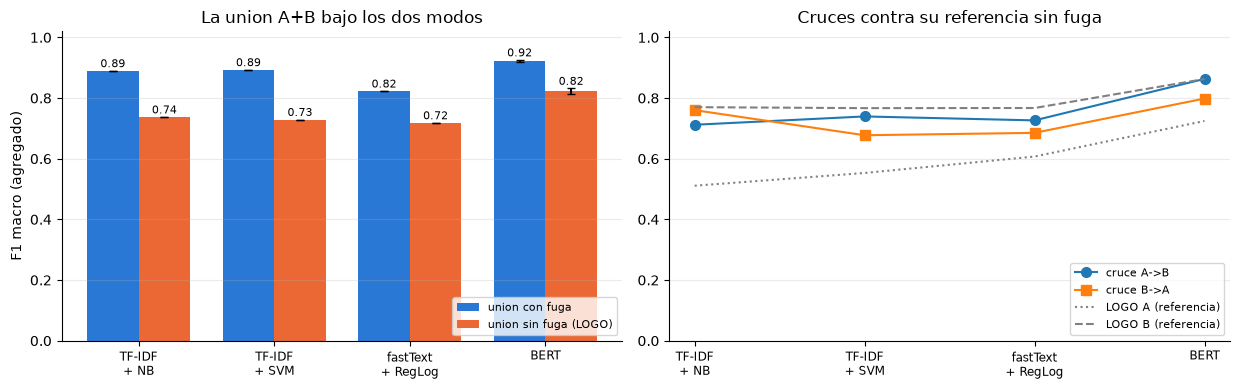

In [6]:
nombres_cortos = {"TF-IDF + MNB": "TF-IDF\n+ NB",
                  "TF-IDF + LinearSVC": "TF-IDF\n+ SVM",
                  "fastText + LogReg": "fastText\n+ RegLog",
                  "BERT (NoRBERT)": "BERT"}
sub = maestra
modelos_aqui = [m for m in MODELOS if m in sub.modelo.values]
x = np.arange(len(modelos_aqui))

fig, (e1, e2) = plt.subplots(1, 2, figsize=(12.5, 4.0))
for despl, condicion, color in ((-0.19, "union con fuga", "#2a78d6"),
                                (0.19, "union sin fuga (LOGO)", "#eb6834")):
    vals = [sub[(sub.modelo == m) & (sub.condicion == condicion)]["F1 macro"].iloc[0]
            for m in modelos_aqui]
    errs = [sub[(sub.modelo == m) & (sub.condicion == condicion)]["desv F1 macro"].iloc[0]
            for m in modelos_aqui]
    e1.bar(x + despl, vals, 0.38, yerr=errs, capsize=3, label=condicion, color=color)
    for xi, (v, e) in enumerate(zip(vals, errs)):
        e1.annotate(f"{v:.2f}", (xi + despl, v + e + 0.012), ha="center", fontsize=8)
e1.set_xticks(x, [nombres_cortos[m] for m in modelos_aqui], fontsize=8.5)
e1.set_title("La union A+B bajo los dos modos")
e1.set_ylim(0, 1.02)
e1.set_ylabel("F1 macro (agregado)")
e1.legend(fontsize=8, loc="lower right")
e1.spines[["top", "right"]].set_visible(False)
e1.yaxis.grid(True, alpha=0.25)

marcas = {"cruce A->B": "o", "cruce B->A": "s"}
for condicion, marca in marcas.items():
    vals = [sub[(sub.modelo == m) & (sub.condicion == condicion)]["F1 macro"].iloc[0]
            for m in modelos_aqui]
    e2.plot(x, vals, marca + "-", label=condicion, ms=7)
ref = pd.read_csv(RUTA_NIVEL1)
ref = ref[ref.modo == "sin fuga (LOGO)"]
for letra, estilo in (("A", ":"), ("B", "--")):
    vals = [ref[(ref.modelo == m) & (ref.corpus == letra)]["F1 macro"].iloc[0]
            for m in modelos_aqui]
    e2.plot(x, vals, estilo, color="gray", label=f"LOGO {letra} (referencia)")
e2.set_xticks(x, [nombres_cortos[m] for m in modelos_aqui], fontsize=8.5)
e2.set_title("Cruces contra su referencia sin fuga")
e2.set_ylim(0, 1.02)
e2.legend(fontsize=8, loc="lower right")
e2.spines[["top", "right"]].set_visible(False)
e2.yaxis.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(os.path.join(DIR_FIGURAS, "nivel2_union_y_cruces.pdf"))
plt.show()

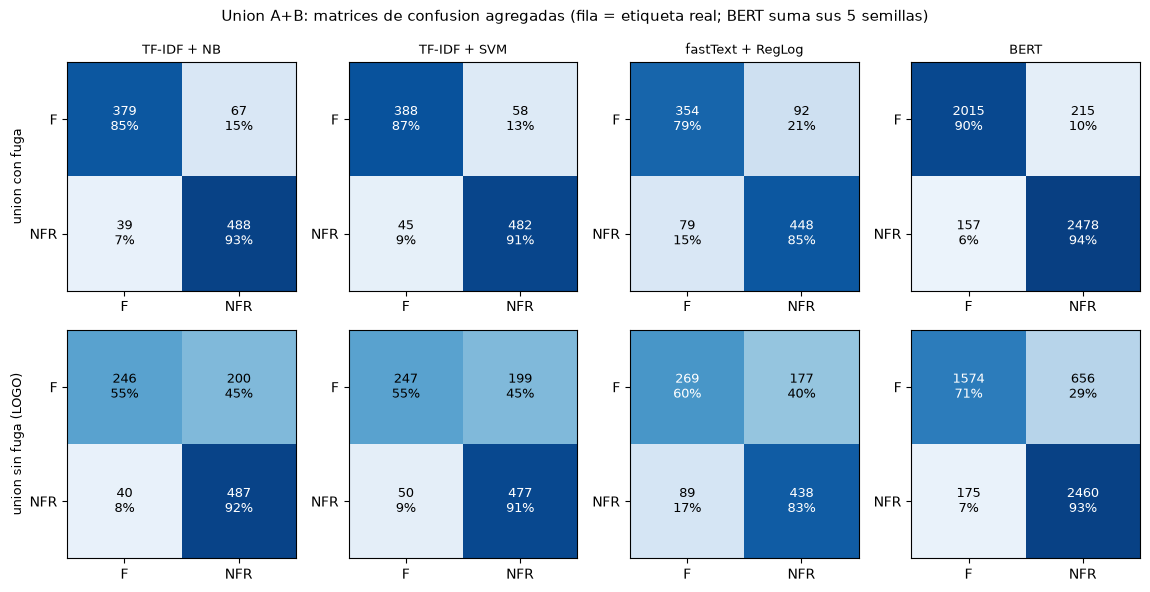

In [7]:
def pred_de(nombre, cond):
    if nombre == "BERT (NoRBERT)":
        return bert.get(cond)
    d = predicciones[cond]
    return d[d.modelo == nombre]

cols = [m for m in MODELOS if pred_de(m, "union_confuga") is not None]
fig, ejes = plt.subplots(2, len(cols), figsize=(2.9 * len(cols), 6.0))
for i, cond in enumerate(("union_confuga", "union_logo")):
    for j, nombre in enumerate(cols):
        d = pred_de(nombre, cond)
        M = confusion_matrix(d.etiqueta, d.prediccion, labels=CLASES)
        pct = M / M.sum(axis=1, keepdims=True)
        eje = ejes[i][j]
        eje.imshow(pct, cmap="Blues", vmin=0, vmax=1)
        for r in range(2):
            for c in range(2):
                color = "white" if pct[r, c] > 0.6 else "black"
                eje.text(c, r, f"{M[r, c]}\n{pct[r, c]:.0%}", ha="center",
                         va="center", color=color, fontsize=9)
        eje.set_xticks([0, 1], CLASES)
        eje.set_yticks([0, 1], CLASES)
        if i == 0:
            eje.set_title(nombres_cortos[nombre].replace("\n", " "), fontsize=9)
        if j == 0:
            eje.set_ylabel(ETIQUETA[cond], fontsize=9)
fig.suptitle("Union A+B: matrices de confusion agregadas "
             "(fila = etiqueta real; BERT suma sus 5 semillas)", fontsize=11)
fig.tight_layout()
fig.savefig(os.path.join(DIR_FIGURAS, "nivel2_confusion_union.pdf"))
plt.show()

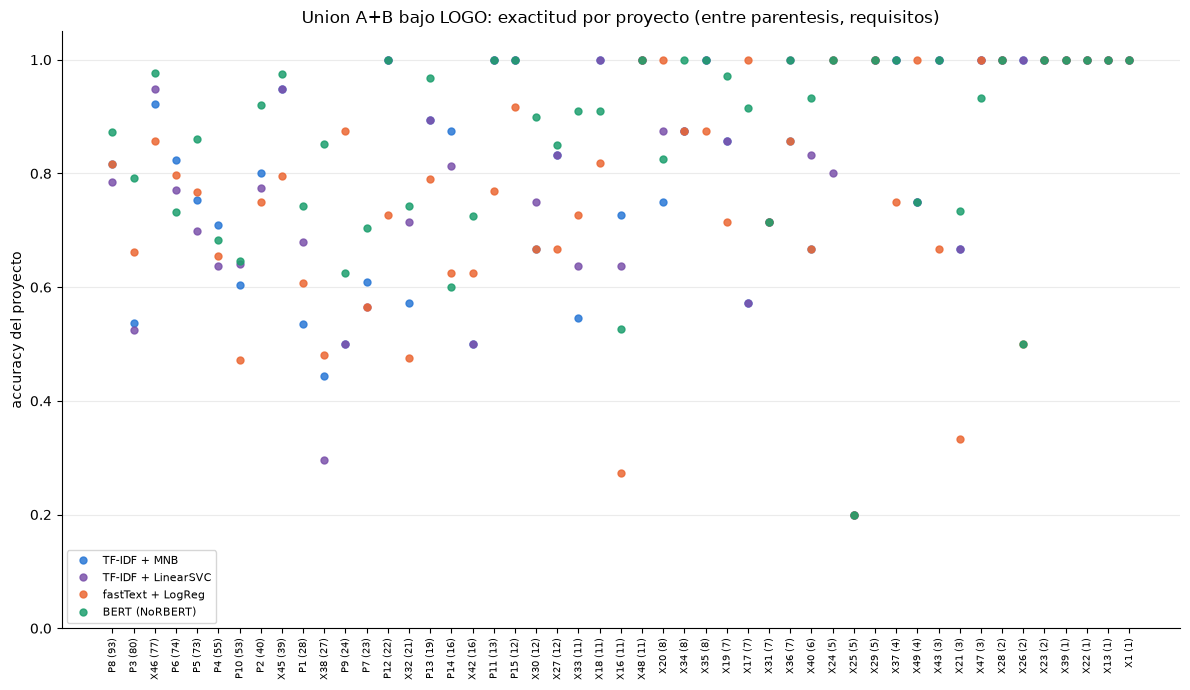

In [8]:
base = predicciones["union_logo"]
tam = base[base.modelo == MODELOS_CLASICOS[0]].groupby("proyecto").size()
orden_p = tam.sort_values(ascending=False).index.tolist()
colores = {"TF-IDF + MNB": "#2a78d6", "TF-IDF + LinearSVC": "#7b52ab",
           "fastText + LogReg": "#eb6834", "BERT (NoRBERT)": "#1d9f6e"}
fig, eje = plt.subplots(figsize=(12, 7.0))
for nombre in MODELOS:
    d = pred_de(nombre, "union_logo")
    if d is None:
        continue
    acc = d.assign(ok=(d.etiqueta == d.prediccion)).groupby("proyecto").ok.mean()
    eje.plot(range(len(orden_p)), acc.loc[orden_p].values, "o", ms=5,
             label=nombre, color=colores[nombre], alpha=0.85)
eje.set_xticks(range(len(orden_p)), [f"{p} ({tam[p]})" for p in orden_p],
               rotation=90, fontsize=7)
eje.set_ylabel("accuracy del proyecto")
eje.set_ylim(0, 1.05)
eje.set_title("Union A+B bajo LOGO: exactitud por proyecto "
              "(entre parentesis, requisitos)")
eje.yaxis.grid(True, alpha=0.25)
eje.spines[["top", "right"]].set_visible(False)
eje.legend(fontsize=8)
fig.tight_layout()
fig.savefig(os.path.join(DIR_FIGURAS, "nivel2_union_por_proyecto.pdf"))
plt.show()

## 5. Salidas

En `datasets/nivel2/`: predicciones por condición (clásicos y BERT), `nivel2_metricas.csv` y las figuras.